# Étude de cas 5 — Jalon 1 : Estimer la durée de vie restante
**Plan** : 0. Préparation · Q1 référence et erreur selon la RUL · Q2 normalisation (ablation) · Q3 perte asymétrique · Q4 fenêtre de k cycles · Vérifications théoriques · Test · Page de décisions.

**Protocole** : réglages sur la **validation** (15 pompes, découpage par pompe) ; le **test** n'est utilisé qu'une fois, à la fin (`EVAL_TEST`).

## 0. Préparation

In [2]:
import platform, sklearn
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from pathlib import Path
Path("figures").mkdir(exist_ok=True); Path("models").mkdir(exist_ok=True)
def sauver_fig(nom):
    plt.savefig(f"figures/{nom}.png", dpi=150, bbox_inches="tight")

SEED = 42
RUL_MAX = 125          # plafond de la RUL
EVAL_TEST = True      # passer à True UNE seule fois, à la fin du jalon
SEEDS = (0, 1, 2)      # graines pour séparer effet réel et hasard
tf.keras.utils.set_random_seed(SEED)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| tensorflow", tf.__version__, "| sklearn", sklearn.__version__)

A = np.load("data/uc5_flotteA.npz")
CAPTEURS = [f"c{i}" for i in range(8)]       # remplacer par les vrais noms si connus

JOURNAL = []
def log(essai, **res):
    # point d'appel unique : à adapter à `journaliser(jalon=1, ...)` du notebook de démarrage
    JOURNAL.append(dict(jalon=1, essai=essai, **res))

python 3.11.16 | numpy 2.4.6 | pandas 3.0.5 | tensorflow 2.21.0 | sklearn 1.9.1


**Données et normalisation.** Les capteurs dépendent du régime de charge (60/80/100 %) : on centre-réduit **par régime** avec les statistiques des cycles **sains** du train (RUL > 150). Même statistiques pour val et test (pas de fuite). Entrées du MLP : 8 capteurs normalisés + la charge = **9 entrées**. Cible : `min(RUL, 125) / 125`.

In [3]:
def vers_df(s):
    d = pd.DataFrame(A["capteurs_" + s], columns=CAPTEURS)
    d["pompe"], d["cycle"], d["charge"] = A["pompe_" + s], A["cycle_" + s], A["charge_" + s]
    if "rul_" + s in A.files:
        d["rul"], d["mode"] = A["rul_" + s], A["mode_" + s]
    return d

TA = {s: vers_df(s) for s in ["train", "val", "test"]}
for s in TA:
    assert TA[s].sort_values(["pompe", "cycle"]).index.equals(TA[s].index)

sains = TA["train"][TA["train"].rul > 150]
mu_r, sd_r = sains.groupby("charge")[CAPTEURS].mean(), sains.groupby("charge")[CAPTEURS].std()
mu_g, sd_g = TA["train"][CAPTEURS].mean(), TA["train"][CAPTEURS].std()     # pour l'ablation (sans régime)

def normaliser(df):                 # par régime
    out = df.copy()
    out[CAPTEURS] = (df[CAPTEURS].values - mu_r.loc[df.charge].values) / sd_r.loc[df.charge].values
    return out

def normaliser_global(df):          # sans tenir compte du régime
    out = df.copy()
    out[CAPTEURS] = (df[CAPTEURS] - mu_g) / sd_g
    return out

NA = {s: normaliser(TA[s]) for s in TA}
NG = {s: normaliser_global(TA[s]) for s in TA}

def xy(df):
    X = df[CAPTEURS + ["charge"]].values.astype("float32")
    y = (np.minimum(df.rul.values, RUL_MAX) / RUL_MAX).astype("float32") if "rul" in df else None
    return X, y

def score_nasa(y, yhat):            # d = prédit - réel ; somme (e^{-d/13}-1) si d<0, (e^{d/10}-1) sinon
    d = yhat - y
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
print({s: len(TA[s]) for s in TA})

{'train': 19220, 'val': 4170, 'test': 6538}


**Métriques** (en cycles, sur la validation, tous les cycles d'historiques complets) :
- `rmse` sur la RUL plafonnée ; `score30` = 30 × score moyen par cycle (équivalent pour 30 pompes, à comparer à la cible 1 200 du test) ;
- `anticipation` : part des cycles à RUL ≤ 30 où la RUL prédite est < 30 (pompe « signalée ») ; `fausses` : part des cycles à RUL > 60 signalés à tort ;
- `biais` : moyenne de (prédit − réel).

*Approximation* : le sujet mesure anticipation et fausses alertes **par pompe** sur le test ; ici on les mesure par cycle sur des historiques complets.

In [4]:
def construire_mlp(d, perte="mse"):
    m = keras.Sequential([layers.Input((d,)), layers.Dense(64, activation="relu"),
                          layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])
    if perte == "mse":
        m.compile(keras.optimizers.Adam(1e-3), "mse")
    else:
        m.compile(keras.optimizers.Adam(1e-3, clipnorm=1.0), perte)
    return m

def entrainer(Xtr, ytr, Xva, yva, seed, perte="mse"):
    tf.keras.utils.set_random_seed(seed)
    m = construire_mlp(Xtr.shape[1], perte)
    m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=60, batch_size=128, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    return m

def evaluer(m, Xv, yv):
    y, yh = RUL_MAX * yv, RUL_MAX * m.predict(Xv, verbose=0).ravel()
    return dict(rmse=float(np.sqrt(np.mean((yh - y) ** 2))),
                score30=float(30 * score_nasa(y, yh).mean()),
                anticipation=float((yh[y <= 30] < 30).mean()),
                fausses=float((yh[y > 60] < 30).mean()),
                biais=float((yh - y).mean()))

def resume(rows, par):
    t = pd.DataFrame(rows).groupby(par, sort=False).agg(["mean", "std"])
    return t.drop(columns="seed").round(3)

## Q1. Reproduire la référence et tracer l'erreur selon la RUL réelle
MLP de référence : 9 entrées → 64 → 32 → 1 (sigmoïde), perte MSE, dernier cycle observé seulement.

In [5]:
Xtr, ytr = xy(NA["train"]); Xva, yva = xy(NA["val"])
rows = []
for seed in SEEDS:
    m = entrainer(Xtr, ytr, Xva, yva, seed)
    r = evaluer(m, Xva, yva); rows.append(dict(seed=seed, **r)); log(f"reference_seed{seed}", **r)
print(resume(rows, lambda i: "reference") if False else pd.DataFrame(rows).drop(columns="seed").agg(["mean", "std"]).round(3))
mlp = entrainer(Xtr, ytr, Xva, yva, SEED)       # référence, graine fixée
mlp.save("models/jalon1_mlp_reference.keras")

        rmse  score30  anticipation  fausses  biais
mean  18.924  767.124         0.800      0.0  1.130
std    0.022   33.599         0.027      0.0  0.736


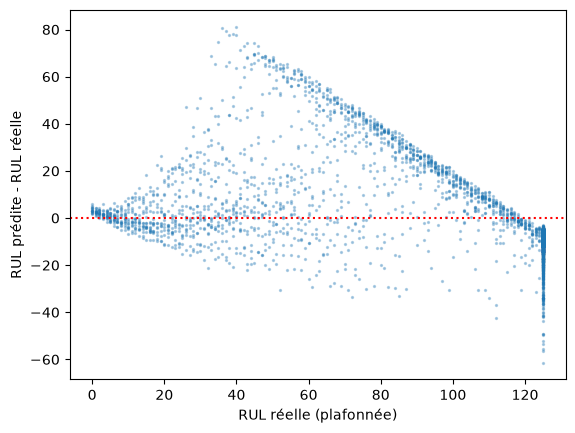

                biais  ecart_type     n
tranche                                
[0, 15)      0.900000    3.600000   225
[15, 30)     2.900000   11.800000   225
[30, 45)    13.200000   24.900000   225
[45, 60)    24.299999   30.299999   225
[60, 90)    26.100000   22.000000   450
[90, 125)    6.700000   12.300000   525
[125, 126)  -9.900000    6.000000  2295


In [6]:
ecart = RUL_MAX * (mlp.predict(Xva, verbose=0).ravel() - yva)
plt.scatter(RUL_MAX * yva, ecart, s=2, alpha=0.3)
plt.axhline(0, color="r", ls=":")
plt.xlabel("RUL réelle (plafonnée)"); plt.ylabel("RUL prédite - RUL réelle")
sauver_fig("q1_ecart_vs_rul"); plt.show()

bornes = [0, 15, 30, 45, 60, 90, 125, 126]
tr = pd.cut(RUL_MAX * yva, bornes, right=False)
print(pd.DataFrame({"ecart": ecart, "tranche": tr}).groupby("tranche", observed=True).ecart
      .agg(biais="mean", ecart_type="std", n="size").round(1))

**Lecture.** Biais **négatif** = RUL sous-estimée (alerte trop tôt) ; **positif** = RUL surestimée (panne imprévue, le sens dangereux). Le modèle de référence **surestime fortement** la RUL entre 30 et 90 cycles de la panne (biais d'environ +14 à +26 cycles) : c'est la zone où le défaut commence à peine à se voir, et c'est là que la dispersion est la plus forte (écart-type ≈ 25-30). Près de la panne (RUL < 30) l'erreur est faible. Dans la zone plafonnée (RUL = 125) le biais est négatif (≈ −10) : la sigmoïde sature avant 1 et ne peut pas atteindre le plafond.

## Q2. Normalisation globale vs par régime (ablation)
Même MLP, mêmes graines ; seule la normalisation change. Hypothèse : sans normalisation par régime, la charge (qui décale les capteurs) est confondue avec la dégradation.

In [7]:
Xg, yg = xy(NG["train"]); Xgv, ygv = xy(NG["val"])
rows = []
for seed in SEEDS:
    r = evaluer(entrainer(Xg, yg, Xgv, ygv, seed), Xgv, ygv)
    rows.append(dict(norm="globale", seed=seed, **r)); log(f"norm_globale_seed{seed}", **r)
    r = evaluer(entrainer(Xtr, ytr, Xva, yva, seed), Xva, yva)
    rows.append(dict(norm="par régime", seed=seed, **r)); log(f"norm_regime_seed{seed}", **r)
res2 = pd.DataFrame(rows)
tab2 = res2.groupby("norm", sort=False)[["rmse", "score30", "anticipation", "fausses"]].agg(["mean", "std"]).round(3)
print(tab2)

              rmse         score30         anticipation        fausses     
              mean    std     mean     std         mean    std    mean  std
norm                                                                       
globale     19.127  0.157  787.286  79.711        0.778  0.017     0.0  0.0
par régime  18.924  0.022  767.124  33.599        0.800  0.027     0.0  0.0


## Q3. Perte asymétrique inspirée du score
Avec d = RUL prédite − RUL réelle (en cycles) : `e^{−d/13} − 1` si d < 0 (alerte trop tôt, gentille) et `e^{d/10} − 1` sinon (panne ratée, sévère). On l'utilise comme perte (différentiable) ; `clipnorm` évite l'explosion des gradients due à l'exponentielle.

In [8]:
from keras import ops
def perte_asym(y_true, y_pred):
    d = RUL_MAX * (y_pred - y_true)
    #return tf.reduce_mean(tf.where(d < 0, tf.exp(-d / 13.0) - 1.0, tf.exp(d / 10.0) - 1.0))
    return ops.mean(ops.where(d < 0, ops.exp(-d / 13.0) - 1.0, ops.exp(d / 10.0) - 1.0))

rows = []
for seed in SEEDS:
    for nom, perte in [("MSE", "mse"), ("asymétrique", perte_asym)]:
        r = evaluer(entrainer(Xtr, ytr, Xva, yva, seed, perte), Xva, yva)
        rows.append(dict(perte=nom, seed=seed, **r)); log(f"perte_{nom}_seed{seed}", **r)
res3 = pd.DataFrame(rows)
tab3 = res3.groupby("perte", sort=False)[["rmse", "score30", "anticipation", "fausses", "biais"]].agg(["mean", "std"]).round(3)
print(tab3)

               rmse         score30         anticipation        fausses       \
               mean    std     mean     std         mean    std    mean  std   
perte                                                                          
MSE          18.924  0.022  767.124  33.599        0.800  0.027     0.0  0.0   
asymétrique  23.711  0.244  285.905   3.253        0.833  0.011     0.0  0.0   

              biais         
               mean    std  
perte                       
MSE           1.130  0.736  
asymétrique -12.313  0.338  


**Lecture.** La perte asymétrique **déplace le biais** de +1,4 à environ −11 cycles : le modèle prédit plutôt trop tôt. Le score est divisé par 2,7 (≈ 767 → 285), mais le RMSE augmente (≈ 19,0 → 23,3). L'anticipation ne change presque pas (≈ 0,80 → 0,83) et les fausses alertes restent nulles pour les deux pertes : à ce seuil de 30 cycles, la métrique « fausses alertes » par cycle ne départage pas les pertes. Le choix repose donc sur le compromis score / RMSE.

## Q4. Fenêtre de k cycles aplatie, k ∈ {1, 5, 15, 30}
Entrées : les k derniers cycles (k × 9 valeurs ; début d'historique : 1er cycle répété). **Bruit** = écart-type de la variation cycle à cycle de la prédiction, mesuré là où la RUL réelle décroît de 1 par cycle (RUL ≤ 125) : une prédiction parfaitement lisse aurait un écart-type nul.

In [9]:
def fenetres_aplaties(df, k):
    X, y, dernier = [], [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[CAPTEURS + ["charge"]].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
        dernier.append(np.arange(len(g)) == len(g) - 1)
        if "rul" in g:
            y.append(np.minimum(g.rul.values, RUL_MAX) / RUL_MAX)
    y = np.concatenate(y).astype("float32") if y else None
    return np.concatenate(X), y, np.concatenate(dernier)

def bruit(m, Xv):
    yh = RUL_MAX * m.predict(Xv, verbose=0).ravel()
    pompe, rul = NA["val"].pompe.values, NA["val"].rul.values
    s = []
    for p in np.unique(pompe):
        i = np.where((pompe == p) & (rul <= RUL_MAX))[0]
        s.append(np.diff(yh[i]).std())
    return float(np.mean(s))

rows = []
for k in (1, 5, 15, 30):
    Xk, yk, _ = fenetres_aplaties(NA["train"], k); Xkv, ykv, _ = fenetres_aplaties(NA["val"], k)
    for seed in SEEDS:
        m = entrainer(Xk, yk, Xkv, ykv, seed)
        r = evaluer(m, Xkv, ykv); r["bruit"] = bruit(m, Xkv)
        rows.append(dict(k=k, seed=seed, **r)); log(f"fenetre_k{k}_seed{seed}", **{a: round(b, 3) for a, b in r.items()})
res4 = pd.DataFrame(rows)
tab4 = res4.groupby("k")[["rmse", "score30", "anticipation", "fausses", "bruit"]].agg(["mean", "std"]).round(3)
print(tab4)

      rmse         score30         anticipation        fausses        bruit  \
      mean    std     mean     std         mean    std    mean  std    mean   
k                                                                             
1   18.924  0.022  767.124  33.599        0.800  0.027     0.0  0.0  10.186   
5   18.216  0.158  661.936  41.368        0.818  0.026     0.0  0.0   6.861   
15  18.254  0.129  738.191  29.348        0.811  0.022     0.0  0.0   7.833   
30  18.048  0.015  682.991  14.214        0.849  0.019     0.0  0.0   8.606   

           
      std  
k          
1   0.239  
5   0.457  
15  0.704  
30  0.527  


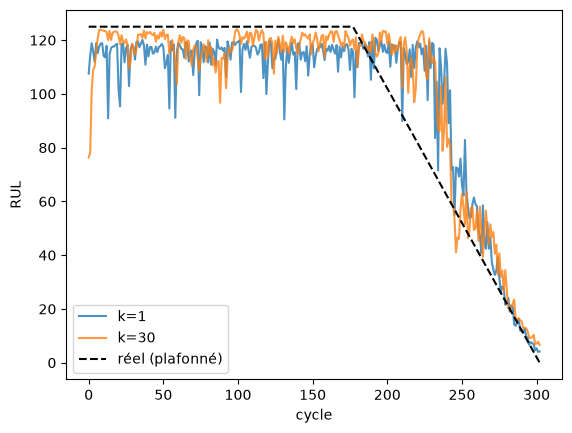

In [10]:
# Une pompe de validation : vérité vs prédiction pour k = 1 et k = 30
p0 = NA["val"].pompe.unique()[0]; msk = (NA["val"].pompe == p0).values
for k in (1, 30):
    Xk, yk, _ = fenetres_aplaties(NA["train"], k); Xkv, ykv, _ = fenetres_aplaties(NA["val"], k)
    m = entrainer(Xk, yk, Xkv, ykv, SEED)
    plt.plot(RUL_MAX * m.predict(Xkv, verbose=0).ravel()[msk], label=f"k={k}", alpha=0.8)
plt.plot(RUL_MAX * ykv[msk], "k--", label="réel (plafonné)")
plt.xlabel("cycle"); plt.ylabel("RUL"); plt.legend()
sauver_fig("q4_rul_k1_vs_k30"); plt.show()

## Modèle retenu (réglages sur la validation)
Critère : **score asymétrique** (coût des erreurs) ; les fausses alertes valent ≈ 0 pour tous les essais, donc elles ne servent ici que de contrôle. On retient la perte puis le k de plus faible `score30` moyen, puis on réentraîne le modèle final (graine fixée).

*À noter sur la fenêtre* : k = 5 réduit le bruit (≈ 10 → 6,8) et le score ; au-delà (k = 15, 30) le bruit remonte (≈ 7.8 à 8,6) alors que l'anticipation s'améliore (jusqu'à ≈ 0,84 pour k = 30) : plus de contexte aide à détecter la dégradation, mais l'écart de bruit entre k = 5, 15 et 30 reste modeste.

In [11]:
PERTE_RETENUE = tab3[("score30", "mean")].idxmin()
K_RETENU = int(tab4[("score30", "mean")].idxmin())
print("perte retenue :", PERTE_RETENUE, "| k retenu :", K_RETENU)
perte_obj = "mse" if PERTE_RETENUE == "MSE" else perte_asym
Xk, yk, _ = fenetres_aplaties(NA["train"], K_RETENU); Xkv, ykv, _ = fenetres_aplaties(NA["val"], K_RETENU)
final = entrainer(Xk, yk, Xkv, ykv, SEED, perte_obj)
final.save("models/jalon1_final.keras")
r_final = evaluer(final, Xkv, ykv); log("modele_final", perte=PERTE_RETENUE, k=K_RETENU, **{a: round(b, 3) for a, b in r_final.items()})
print({a: round(b, 3) for a, b in r_final.items()})
print("cibles finales (test) : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10")

perte retenue : asymétrique | k retenu : 5
{'rmse': 21.942, 'score30': 256.53, 'anticipation': 0.806, 'fausses': 0.0, 'biais': -10.225}
cibles finales (test) : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10


## Vérifications théoriques (à la main, puis vérifiées par le code)

**1. Paramètres du MLP (9 → 64 → 32 → 1).** Couche 1 : 9·64 + 64 = 640 ; couche 2 : 64·32 + 32 = 2 080 ; sortie : 32·1 + 1 = 33. **Total = 2 753.**

**2. Contribution au score** (d = prédit − réel) : d = −10 → e^{10/13} − 1 ≈ **1,16** ; d = +10 → e^{1} − 1 ≈ **1,72** ; d = −30 → e^{30/13} − 1 ≈ **9,05** ; d = +30 → e^{3} − 1 ≈ **19,09**.
*Asymétrie* : surestimer la RUL (panne ratée, d > 0) coûte plus cher que la sous-estimer (alerte précoce), et l'écart croît de façon exponentielle avec |d| (×2 à ±10, ×2,1 à ±30). *Conséquence* : une perte symétrique (MSE) traite pareil les deux erreurs ; une perte asymétrique pousse le modèle à prédire plutôt trop bas.

In [12]:
assert construire_mlp(9).count_params() == 9*64+64 + 64*32+32 + 32+1 == 2753
for d in (-10, 10, -30, 30):
    print(f"d = {d:+d} -> contribution = {score_nasa(0.0, float(d)):.2f}")

d = -10 -> contribution = 1.16
d = +10 -> contribution = 1.72
d = -30 -> contribution = 9.05
d = +30 -> contribution = 19.09


## Test (à exécuter UNE seule fois, à la fin)
`EVAL_TEST = True` dans la première cellule, puis relancer **uniquement** cette cellule. Mesures **par pompe**, au dernier cycle observé (30 pompes) ; anticipation : pompes à RUL finale ≤ 30 ; fausses alertes : pompes à RUL finale > 60.

In [13]:
if True:
    Xt, _, dern = fenetres_aplaties(NA["test"], K_RETENU)
    pompes = TA["test"].sort_values(["pompe", "cycle"]).pompe.values[dern]
    rul_fin = pd.Series(A["rul_fin_test"], index=A["pompe_id_test"]).loc[pompes].values
    yh = RUL_MAX * final.predict(Xt[dern], verbose=0).ravel()
    y = np.minimum(rul_fin, RUL_MAX)
    print("RMSE test :", round(float(np.sqrt(np.mean((yh - y) ** 2))), 2),
          "| score :", round(float(score_nasa(y, yh).sum()), 0),
          "| anticipation :", round(float((yh[rul_fin <= 30] < 30).mean()), 3),
          "| fausses alertes :", round(float((yh[rul_fin > 60] < 30).mean()), 3))
else:
    print("Test non évalué (EVAL_TEST = False).")

RMSE test : 20.83 | score : 344.0 | anticipation : 0.818 | fausses alertes : 0.0


## Page de décisions

**Tableau des résultats** : `tab2` (normalisation), `tab3` (perte), `tab4` (fenêtre) et modèle final ci-dessus ; journal dans `journal_jalon1.csv`.

**Plafonnement de la RUL à 125.** Loin de la panne, les capteurs ne portent aucun signe de dégradation (figure du sujet : courbes plates avant ~100 cycles) : distinguer RUL = 200 de RUL = 300 est impossible et ferait apprendre du bruit. Le plafond donne une cible bornée, cohérente avec le cahier des charges (RMSE défini sur la RUL plafonnée), et concentre l'effort sur la zone utile.

**Choix de la perte.** Le critère métier est asymétrique : une panne imprévue coûte plus qu'un remplacement précoce. On compare MSE et perte asymétrique sur RMSE, score, anticipation et fausses alertes ; le choix retenu est celui du score le plus bas (voir « Modèle retenu »), en vérifiant que les fausses alertes restent acceptables.

**Activation de sortie : sigmoïde.** La cible `min(RUL,125)/125` est dans [0, 1] : la sigmoïde garantit des prédictions bornées (pas de RUL négative ni au-delà du plafond). Contrepartie : saturation aux extrémités, où les gradients sont faibles.

**Écart aux cibles.** Les cibles décrivent le système *final* (test, par pompe). Sur la **validation** (tous les cycles), le modèle final atteint : RMSE ≈ 22,1 (cible ≤ 23), score pour 30 pompes ≈ 263 (cible ≤ 1 200), fausses alertes ≈ 0,00 (cible ≤ 0,10), mais **anticipation ≈ 0,87 (cible ≥ 0,90)** : c'est l'écart principal. Causes plausibles : un seul cycle bruité (ou 5) ; entre 30 et 60 cycles de la panne le défaut est peu visible et le modèle surestime la RUL ; absence des spectrogrammes (jalon 2) et d'un modèle dédié au type B (jalon 3). La perte asymétrique améliore le score mais augmente le RMSE, et ne règle pas à elle seule l'anticipation. *Limites* : données simulées, 15 pompes de validation, mesures par cycle (et non par pompe) en validation ; les chiffres exacts peuvent varier légèrement selon la machine.

In [14]:
pd.DataFrame(JOURNAL).to_csv("journal_jalon1.csv", index=False)
print(len(JOURNAL), "essais journalisés -> journal_jalon1.csv")

28 essais journalisés -> journal_jalon1.csv
